# Rapport du projet : moteur d'analyse de logs sécurisé

Projet final de Python, ING3.

Auteurs : Benjamin Boyer, Gabriel Guery, Ismail Yacoub et Ilyan Dalmassi.

Ce notebook présente notre travail et montre le moteur en action. Il ne
contient pas de logique de traitement : tout le code se trouve dans le
package `logstream`. Ici, on se contente de l'importer, de l'exécuter sur le
jeu de test et de tracer quelques graphiques, comme le demande l'énoncé.

Le rapport suit l'ordre des modules :

1. L'environnement et l'organisation du code
2. Module 1 : la lecture des fichiers avec des générateurs
3. Module 2 : le pipeline de transformation et le match-case
4. Module 3 : les statistiques, les ensembles et la détection de force brute
5. Module 4 : le moteur de règles et l'audit des variables
6. Une mesure de la mémoire, générateur contre liste
7. Le bilan

## 1. Environnement et architecture

In [1]:
import sys
from pathlib import Path

# Le notebook est dans notebooks/ : on ajoute la racine du projet au path.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

print("Python             :", sys.version.split()[0])
print("Environnement isolé :", sys.prefix != sys.base_prefix, f"({sys.prefix})")

Python             : 3.13.5
Environnement isolé : True (/home/benjamin/Téléchargements/projet_python/.venv)


Nous travaillons dans un environnement virtuel, et les dépendances sont
figées dans `requirements.txt` avec `pip freeze`.

Le point d'entrée est `main.py`. Le package `logstream` contient un fichier
par thème : `ingestion.py` et `parsing.py` pour le module 1, `pipeline.py`
pour le module 2, `aggregation.py` et `detection.py` pour le module 3,
`rules.py` et `audit.py` pour le module 4. Autour, on trouve `config.py` pour
les constantes, `models.py` pour les types de données, `exceptions.py` pour
nos exceptions, `simulator.py` pour générer les données de test et
`reporting.py` pour l'affichage. Le dossier `data` contient le jeu de test et
le dossier `tests` les tests pytest.

In [2]:
import matplotlib.pyplot as plt

# Charte graphique commune à tous les graphiques du rapport.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
LEVEL_COLORS = {"INFO": BLUE, "WARNING": "#fab219",
                "ERROR": "#ec835a", "CRITICAL": "#d03b3b"}

plt.rcParams.update({
    "figure.figsize": (8, 3.6), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": MUTED,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "lines.linewidth": 2,
})


def hbar(labels, values, title, color=BLUE, xlabel=""):
    """Barres horizontales avec étiquettes de valeur."""
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(labels) + 1))
    colors = color if isinstance(color, list) else [color] * len(labels)
    bars = ax.barh(labels, values, color=colors, height=0.6)
    ax.bar_label(bars, padding=4, color=MUTED, fontsize=9)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.margins(x=0.12)
    plt.show()

## 2. Module 1 : lire les fichiers sans les charger en mémoire

`read_log_file` est un générateur. L'appeler ne lit encore rien : on obtient
un objet qui donnera les lignes une par une, au moment où on les demande.
`read_log_sources` enchaîne plusieurs fichiers grâce à `yield from`.

Dans la cellule suivante, on remarque que l'objet générateur ne pèse que
quelques centaines d'octets, alors que le fichier en fait plusieurs
centaines de milliers.

In [3]:
import inspect
from logstream.config import DATA_DIR, DEFAULT_LOG_FILES
from logstream.ingestion import read_log_file, read_log_sources

PATHS = [DATA_DIR / name for name in DEFAULT_LOG_FILES]

lines = read_log_file(PATHS[0])
print("Type :", type(lines).__name__, ", est un générateur :", inspect.isgenerator(lines))
print("Taille de l'objet générateur :", sys.getsizeof(lines), "octets")
print("Taille du fichier             :", PATHS[0].stat().st_size, "octets")
print("Première ligne :", next(lines))
lines.close()  # on libère le fichier

total = sum(1 for _ in read_log_sources(PATHS))  # parcours sans liste
print(f"\n{total} lignes lues dans {len(PATHS)} fichiers via yield from")

Type : generator , est un générateur : True
Taille de l'objet générateur : 264 octets
Taille du fichier             : 619249 octets
Première ligne : 2026-10-20T06:00:01 | INFO | 192.168.1.25:443/TCP | user008 | {"method": "GET", "path": "/index.html", "status": 200}

15225 lignes lues dans 3 fichiers via yield from


Chaque ligne est ensuite découpée en dictionnaire. L'horodatage devient un
`datetime`, le niveau reste une chaîne, la source devient un tuple immuable
`(IP, Port, Protocole)` et le contenu (le payload) est soit un dictionnaire
si c'était du JSON, soit une simple chaîne.

In [4]:
from pprint import pprint
from logstream.parsing import decode_line, parse_text_line

record = parse_text_line(
    '2026-10-20T08:15:32 | WARNING | 203.0.113.7:22/SSH | root | '
    '{"event": "login", "status": "failed"}'
)
pprint(record, sort_dicts=False)
print("\nsource est un tuple :", isinstance(record["source"], tuple))

for line in ['{"timestamp": "2026-10-20T08:00:00", "level": "ERROR", "code": 500, "ip": "10.0.0.3"}',
             "CONN 2026-10-20T08:00:10 203.0.113.66 23 TCP",
             "2026-10-20T08:00:20 | CRITICAL | 10.0.0.1:0/UDP | - | Disque plein"]:
    decoded = decode_line(line)
    print(f"{type(decoded).__name__:>5} : {line[:60]}")

{'timestamp': datetime.datetime(2026, 10, 20, 8, 15, 32),
 'level': 'WARNING',
 'source': ('203.0.113.7', 22, 'SSH'),
 'ip': '203.0.113.7',
 'user_id': 'root',
 'payload': {'event': 'login', 'status': 'failed'},
 'category': 'AUTH',
 'origin_format': 'raw',
 'message': ''}

source est un tuple : True
 dict : {"timestamp": "2026-10-20T08:00:00", "level": "ERROR", "code
tuple : CONN 2026-10-20T08:00:10 203.0.113.66 23 TCP
  str : 2026-10-20T08:00:20 | CRITICAL | 10.0.0.1:0/UDP | - | Disque


## 3. Module 2 : le pipeline de transformation

`build_pipeline` enchaîne des `map()` et des `filter()`, avec des lambdas et
`filter(None, ...)` pour retirer les entrées vides ou illisibles.

Au milieu de ce pipeline, la fonction `route_entry` utilise un match-case
pour reconnaître le format de chaque entrée : une chaîne brute, un
dictionnaire contenant un niveau et un code, ou un tuple de connexion. Si
l'entrée ne correspond à rien, elle renvoie `None` et l'entrée est écartée.

In [5]:
from datetime import datetime
from logstream.pipeline import route_entry

samples = [
    "2026-10-20T08:00:00 | INFO | 10.0.0.2:443/TCP | bob | Service démarré",
    {"timestamp": "2026-10-20T08:00:05", "level": "ERROR", "code": 503, "ip": "10.0.0.3"},
    (datetime(2026, 10, 20, 8, 0, 10), "203.0.113.66", 3389, "TCP"),
    ("10.0.0.9", 22, "SSH"),
    "ligne corrompue",
    12345,
]
for sample in samples:
    result = route_entry(sample)
    status = f"format {result['origin_format']}, catégorie {result['category']}" if result else "rejetée"
    print(f"{type(sample).__name__:>8} : {status}")

     str : format raw, catégorie SYSTEM
    dict : format dict, catégorie HTTP
   tuple : format tuple, catégorie NETWORK
   tuple : format tuple, catégorie NETWORK
     str : rejetée
     int : rejetée


In [6]:
from itertools import islice
from logstream.pipeline import PipelineMetrics, build_pipeline

metrics = PipelineMetrics()
pipeline = build_pipeline(read_log_sources(PATHS), metrics)
print("Avant de parcourir le pipeline :", dict(metrics.counters))
print("Rien n'a encore été calculé.")

for rec in islice(pipeline, 3):
    print(rec["message"])

for _ in pipeline:  # on consomme la suite
    pass
pprint(metrics.as_dict())

Avant de parcourir le pipeline : {}
Rien n'a encore été calculé.
[2026-10-20 06:00:01] INFO        192.168.1.25:443   TCP   user=user008    HTTP    GET /index.html (statut 200)
[2026-10-20 06:00:04] ERROR      198.51.100.99:443   TCP   user=user020    HTTP    code 504 : Erreur serveur HTTP 504
[2026-10-20 06:00:23] INFO        192.168.1.10:80    TCP   user=user025    HTTP    GET /dashboard (statut 200)
{'non_empty_entries': 15137,
 'parsed_records': 15036,
 'raw_entries': 15225,
 'rejected': 131,
 'valid_records': 15006}


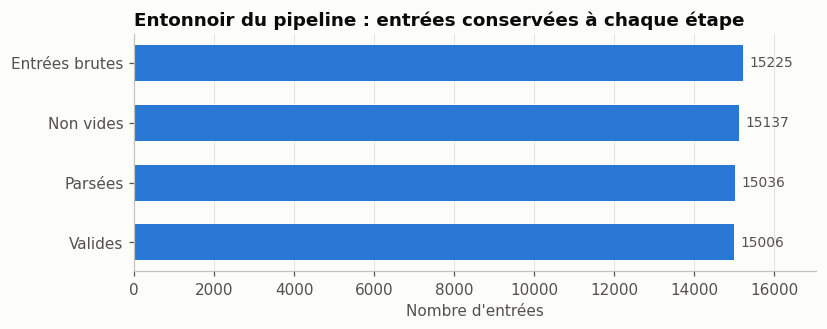

In [7]:
c = metrics.counters
hbar(["Entrées brutes", "Non vides", "Parsées", "Valides"],
     [c["raw_entries"], c["non_empty_entries"], c["parsed_records"], c["valid_records"]],
     "Entonnoir du pipeline : entrées conservées à chaque étape",
     xlabel="Nombre d'entrées")

## 4. Module 3 : statistiques et détection

Un seul parcours du flux suffit à remplir tous les compteurs. Ce sont des
`defaultdict(int)` : demander un niveau jamais rencontré renvoie 0 au lieu de
lever une `KeyError`. Les adresses IP sont rangées dans des `set`, et comme
les tuples `(IP, Port, Protocole)` sont hachables, on peut aussi garder
l'ensemble des connexions distinctes.

In [8]:
from logstream.aggregation import collect_statistics, compare_ip_sets, analyze_error_ips, top_n
from logstream.config import SEVERITY_ORDER
from logstream.ingestion import load_blacklist

stats = collect_statistics(build_pipeline(read_log_sources(PATHS)))
blacklist = load_blacklist(DATA_DIR / "blacklist.txt")

print("Type des compteurs :", type(stats.by_level).__name__)
print("Niveau jamais vu   :", stats.by_level["DEBUG"], "(pas de KeyError)")
print("IP actives         :", len(stats.active_ips))
print("IP en erreur       :", len(stats.error_ips))
print("Connexions uniques :", len(stats.connections), ", par exemple", next(iter(stats.connections)))
print("Liste noire        :", type(blacklist).__name__, sorted(blacklist))

Type des compteurs : defaultdict
Niveau jamais vu   : 0 (pas de KeyError)
IP actives         : 46
IP en erreur       : 14
Connexions uniques : 276 , par exemple ('198.51.100.99', 80, 'TCP')
Liste noire        : frozenset ['185.220.101.4', '198.51.100.23', '203.0.113.66', '45.33.32.156', '91.189.0.17']


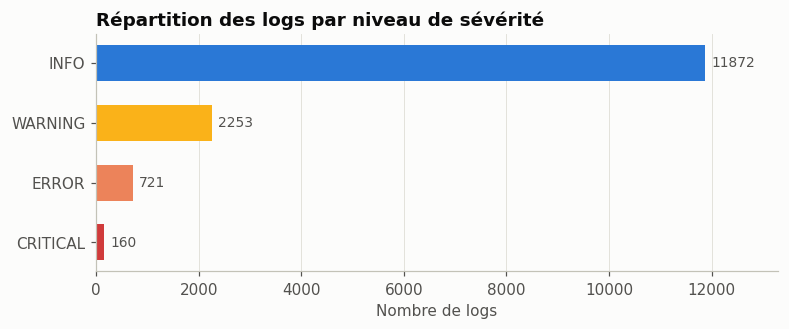

In [9]:
hbar(list(SEVERITY_ORDER), [stats.by_level[l] for l in SEVERITY_ORDER],
     "Répartition des logs par niveau de sévérité",
     color=[LEVEL_COLORS[l] for l in SEVERITY_ORDER], xlabel="Nombre de logs")

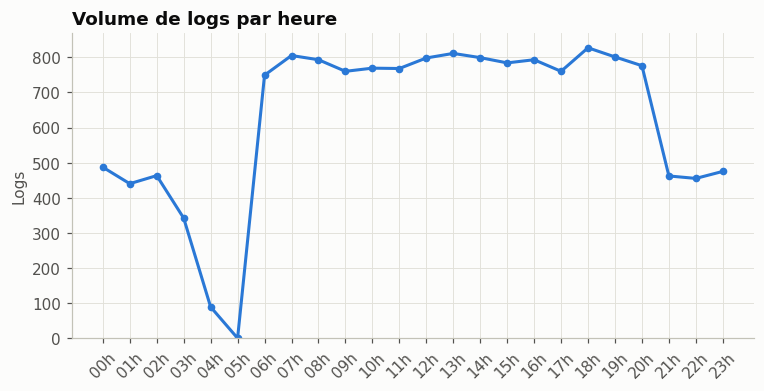

In [10]:
hours = [f"{h:02d}h" for h in range(24)]  # toutes les heures, même vides
fig, ax = plt.subplots()
ax.plot(hours, [stats.by_hour.get(h, 0) for h in hours], color=BLUE, marker="o", markersize=4)
ax.set_title("Volume de logs par heure")
ax.set_ylabel("Logs")
ax.set_ylim(bottom=0)
ax.tick_params(axis="x", rotation=45)
plt.show()

On compare ensuite les IP actives (un `set`) avec la liste noire (un
`frozenset`, qui ne peut pas être modifié). L'union `|` réunit les deux,
l'intersection `&` donne les IP blacklistées qui ont été actives, la
différence `-` ce qui est dans l'un mais pas dans l'autre, et la différence
symétrique `^` ce qui n'est que d'un seul côté.

union                     48  ['10.0.0.1', '10.0.0.10', '10.0.0.11']
intersection               3  ['185.220.101.4', '198.51.100.23', '203.0.113.66']
active_not_blacklisted    43  ['10.0.0.1', '10.0.0.10', '10.0.0.11']
blacklisted_inactive       2  ['45.33.32.156', '91.189.0.17']
symmetric_difference      45  ['10.0.0.1', '10.0.0.10', '10.0.0.11']

frozenset({'198.51.100.23', '203.0.113.66', '185.220.101.4'})


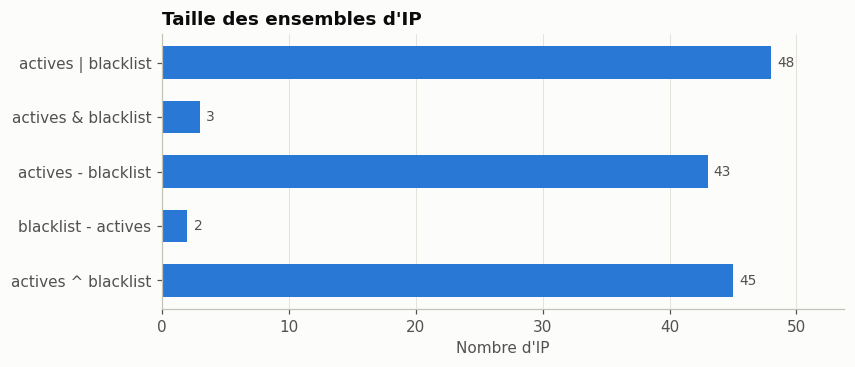

In [11]:
ip_sets = compare_ip_sets(stats.active_ips, blacklist)
for name, values in ip_sets.items():
    print(f"{name:<24} {len(values):>3}  {sorted(values)[:3]}")

print()
pprint(analyze_error_ips(stats.error_ips, blacklist)["known_threats"])

labels = {"union": "actives | blacklist", "intersection": "actives & blacklist",
          "active_not_blacklisted": "actives - blacklist",
          "blacklisted_inactive": "blacklist - actives",
          "symmetric_difference": "actives ^ blacklist"}
hbar([labels[k] for k in ip_sets], [len(v) for v in ip_sets.values()],
     "Taille des ensembles d'IP", xlabel="Nombre d'IP")

Pour la force brute, la boucle `while` découpe le flux en lots et la boucle
`for` parcourt les événements de chaque lot. `continue` passe les événements
qui ne sont pas des tentatives de connexion, et `break` arrête tout si on a
atteint le nombre maximal d'alertes. Le `else` de chaque boucle ne s'exécute
que si elle est allée jusqu'au bout sans `break` : c'est ce qui nous permet
de savoir si l'analyse est complète.

Une IP est signalée lorsqu'elle accumule au moins 5 échecs de connexion en
moins de 5 minutes.

Analyse complète : True, cycles complets : 31
Échecs de connexion : 1601, attaques détectées : 70
    198.51.100.23 : 5 échecs en 12s sur user001
    198.51.100.23 : 5 échecs en 11s sur backup
    198.51.100.99 : 5 échecs en 11s sur admin
      203.0.113.7 : 5 échecs en 8s sur backup
    198.51.100.23 : 5 échecs en 8s sur admin


Limite de 3 alertes atteinte : arrêt



Avec max_alerts=3, l'analyse est complète : False (5337 événements traités sur 15006)


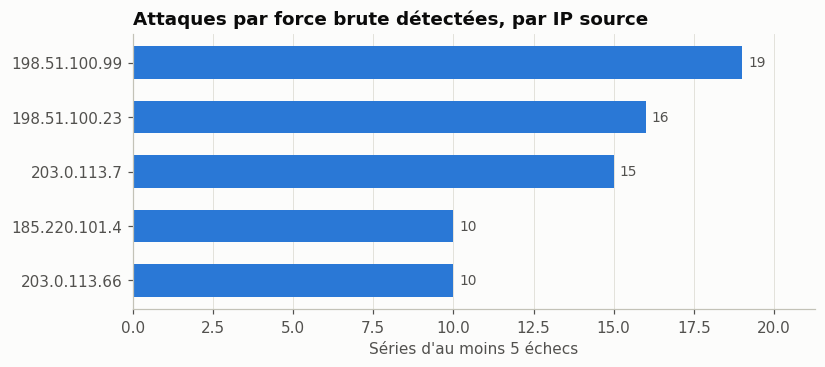

In [12]:
from logstream.aggregation import count_by
from logstream.detection import detect_brute_force

result = detect_brute_force(build_pipeline(read_log_sources(PATHS)), threshold=5)
print(f"Analyse complète : {result.complete}, cycles complets : {result.completed_cycles}")
print(f"Échecs de connexion : {result.failed_logins}, attaques détectées : {len(result.alerts)}")
for alert in result.alerts[:5]:
    print(" ", alert)

partial = detect_brute_force(build_pipeline(read_log_sources(PATHS)), max_alerts=3)
print(f"\nAvec max_alerts=3, l'analyse est complète : {partial.complete} "
      f"({partial.processed_events} événements traités sur {result.processed_events})")

per_ip = top_n(count_by(result.alerts, lambda alert: alert.ip), 10)
hbar([ip for ip, _ in per_ip], [n for _, n in per_ip],
     "Attaques par force brute détectées, par IP source", xlabel="Séries d'au moins 5 échecs")

## 5. Module 4 : le moteur de règles

`apply_security_rules(*args, **kwargs)` reçoit les règles dans `*args` et les
réglages dans `**kwargs`. Les règles sont de simples fonctions qu'on passe en
argument comme n'importe quelle valeur. On peut donc lui donner n'importe
quelle fonction, même une lambda écrite sur le moment, comme ci-dessous.

Règles découvertes via globals() : ['rule_blacklisted_ip', 'rule_critical_event', 'rule_suspicious_port', 'rule_injection_attempt', 'rule_off_hours_error']
Paramètres transmis aux règles : {'blacklist': 'frozenset'}
Logs contrôlés : 15006 , alertes : 2286


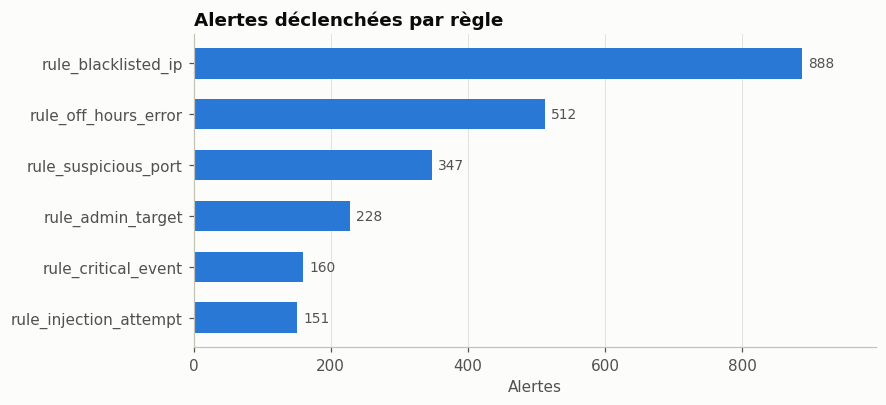

In [13]:
from logstream.rules import apply_security_rules, available_rules, make_off_hours_rule

print("Règles découvertes via globals() :", list(available_rules()))

# Règle personnalisée : une lambda passée en argument comme les autres.
rule_admin = lambda record, **_: "Compte admin ciblé" if record["user_id"] == "admin" else None
rule_admin.__name__ = "rule_admin_target"

report = apply_security_rules(
    *available_rules().values(), rule_admin, make_off_hours_rule(8, 18),
    records=build_pipeline(read_log_sources(PATHS)),
    blacklist=blacklist,
)
print("Paramètres transmis aux règles :", report.config)
print("Logs contrôlés :", report.records_checked, ", alertes :", report.total_hits)

hits = top_n(report.hits_by_rule, 10)
hbar([name for name, _ in hits], [n for _, n in hits],
     "Alertes déclenchées par règle", xlabel="Alertes")

Pour l'audit, on passe à `build_audit_report` le résultat de `globals()` ou
de `locals()`. Pour chaque variable, il relève son type, sa taille en mémoire
et un aperçu de sa valeur. `main.py` fait la même chose à la fin de son
exécution et enregistre le résultat dans `output/audit_report.json`.

In [14]:
from logstream.audit import build_audit_report, format_scope_table


def exemple_fonction():
    seuil = 5
    ips_suspectes = {"203.0.113.7", "198.51.100.99"}
    flux = build_pipeline(read_log_sources(PATHS))  # générateur : quelques octets
    return build_audit_report(fonction_locals=locals())


audit = build_audit_report(notebook_globals=globals())
print(format_scope_table(audit["scopes"]["notebook_globals"]["variables"], limit=10))
print()
print(format_scope_table(exemple_fonction()["scopes"]["fonction_locals"]["variables"]))

Variable                 Type                 Taille (o)
--------------------------------------------------------
AXIS                     str                          48
BLUE                     str                          48
DATA_DIR                 PosixPath                   112
DEFAULT_LOG_FILES        tuple                        64
GRID                     str                          48
INK                      str                          48
In                       list                        184
LEVEL_COLORS             dict                        184
MUTED                    str                          48
ORANGE                   str                          48
... (61 autres variables)

Variable                 Type                 Taille (o)
--------------------------------------------------------
flux                     generator                   232
ips_suspectes            set                         216
seuil                    int                          28


## 6. Générateur contre liste : combien de mémoire ?

Pour vérifier que notre approche tient ses promesses, on génère des fichiers
de plus en plus gros et on mesure le pic de mémoire avec `tracemalloc`, de
deux façons. La première met tous les enregistrements dans une liste avec
`list(...)`. La seconde utilise notre pipeline et traite les lignes au fur et
à mesure.

In [15]:
import tempfile
import tracemalloc
from logstream.simulator import generate_auth_lines, write_lines


def peak_kib(func):
    tracemalloc.start()
    func()
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1024


sizes, list_peaks, gen_peaks = [], [], []
with tempfile.TemporaryDirectory() as tmp:
    for n in (2_000, 5_000, 10_000, 20_000):
        path = Path(tmp) / f"auth_{n}.log"
        write_lines(path, generate_auth_lines(n))
        sizes.append(n)
        list_peaks.append(peak_kib(lambda: list(build_pipeline(read_log_file(path)))))
        gen_peaks.append(peak_kib(lambda: collect_statistics(build_pipeline(read_log_file(path)))))
        print(f"{n:>7} lignes : liste {list_peaks[-1]:>9.0f} Kio, générateur {gen_peaks[-1]:>6.0f} Kio")

   2000 lignes : liste      2083 Kio, générateur     39 Kio


   5000 lignes : liste      5183 Kio, générateur     62 Kio


  10000 lignes : liste     10507 Kio, générateur     45 Kio


  20000 lignes : liste     21127 Kio, générateur     44 Kio


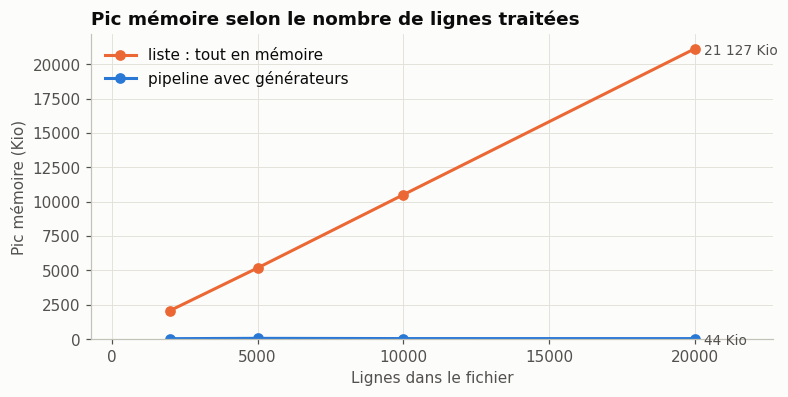

In [16]:
fig, ax = plt.subplots()
ax.plot(sizes, list_peaks, color=ORANGE, marker="o", label="liste : tout en mémoire")
ax.plot(sizes, gen_peaks, color=BLUE, marker="o", label="pipeline avec générateurs")
for series, color in ((list_peaks, ORANGE), (gen_peaks, BLUE)):
    ax.annotate(f"{series[-1]:,.0f} Kio".replace(",", " "), (sizes[-1], series[-1]),
                textcoords="offset points", xytext=(6, -4), color=MUTED, fontsize=9)
ax.set_title("Pic mémoire selon le nombre de lignes traitées")
ax.set_xlabel("Lignes dans le fichier")
ax.set_ylabel("Pic mémoire (Kio)")
ax.set_ylim(bottom=0)
ax.margins(x=0.15)
ax.legend(frameon=False, loc="upper left")
plt.show()

Avec la liste, la mémoire grimpe proportionnellement au nombre de lignes. Avec
le pipeline, elle reste presque au même niveau, parce qu'on ne garde que les
compteurs et les ensembles d'IP distinctes. Sur le jeu complet, `main.py`
traite de 15 000 à 450 000 lignes avec un pic qui reste entre 1 et 2 Mo.

## 7. Bilan

Nous avons couvert tous les points du cahier des charges.

Pour le module 1, `read_log_file` lit les fichiers ligne par ligne avec
`yield`, et `read_log_sources` en enchaîne plusieurs avec `yield from`.
Chaque ligne devient un dictionnaire typé, et les métadonnées de connexion
sont stockées dans un tuple `(IP, Port, Protocole)`.

Pour le module 2, `build_pipeline` utilise `map()`, `filter()`, des lambdas et
`filter(None, ...)`. La normalisation et les messages en f-string sont dans
`normalize_record`, et le match-case qui reconnaît les trois formats est dans
`route_entry`.

Pour le module 3, les IP en erreur sont rangées dans un `set`, la liste noire
est un `frozenset` comparé avec les opérateurs `|`, `&`, `-` et `^`, et les
compteurs sont des `defaultdict`. La détection de force brute utilise une
boucle `while` contenant une boucle `for`, avec `break`, `continue` et `else`.

Pour le module 4, `apply_security_rules(*args, **kwargs)` reçoit les règles
comme des fonctions ordinaires, et l'audit exploite `globals()` et `locals()`
pour produire un rapport.

Ce projet nous a surtout appris à penser en flux : au lieu de charger les
données puis de les traiter, on décrit une suite d'étapes que chaque ligne
traverse. Le code est plus court, et la mémoire n'est plus un problème.